# Análisis Expresión Genética

Para nuestros modelos biologicos, utilizaremos el lenguaje karva. Este lenguaje nos permite definir operaciones complejas como una secuencia de enteros, que se traduce a un árbol que nos define la jerarquía de operaciones.

Para nuestro problema, no nos centraremos en explicar este lenguaje. Simplemente mostramos un ejemplo que hemos hecho con python que nos permite trabajar con genes, cromosomas y operaciones entre estos.

Además, cómo nuestro objetivo es mejorar una regresión lineal con nuevos atributos, hemos definido un sesgo en la aleatoriedad de las mutaciones y de la generación de poblaciones hacia funciones no lineales. Para reducir el espacio de búsqueda.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dataprocessor import datos_test_train
from utils import *
from gepkarva import gen, Cromosoma

In [ ]:
# Cargar los datos
dfDiabetes = pd.read_csv("rawdata/Diabetes.csv")
dfCalifornia = pd.read_csv("rawdata/California.csv")

proporcion = 0.2
seed = 321938
rng = np.random.default_rng(seed)
dfD_train, dfD_test = datos_test_train(dfDiabetes, test_size=proporcion, rng=rng)
dfC_train, dfC_test = datos_test_train(dfCalifornia, test_size=proporcion, rng=rng)

---

In [3]:
def decodificar(g):
    """Karva legible: cabeza | cola."""
    f = lambda s: f"{s:.3g}" if isinstance(s, float) else str(s)
    sim = [f(g.correspondencia[s]) for s in g.karva]
    return " ".join(sim[:g.h]) + "  |  " + " ".join(sim[g.h:])

def dos_gen(a, b, ta, tb):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    a.plot_gen(ax=ax[0]); ax[0].set_title(ta)
    b.plot_gen(ax=ax[1]); ax[1].set_title(tb)
    plt.show()

# Funciones primitivas (`aplicar`)
---
Cada símbolo de función se aplica a vectores. Aquí se dibuja cada una: las de aridad 1 como curva, las de aridad 2 como mapa de contorno de $f(x,y)$. Notar que `H` tiene aridad 2 pero **sólo usa el primer argumento** (`sin(a)·cos(a)`), y que `/` y `R` están protegidas contra divisiones por ~0.

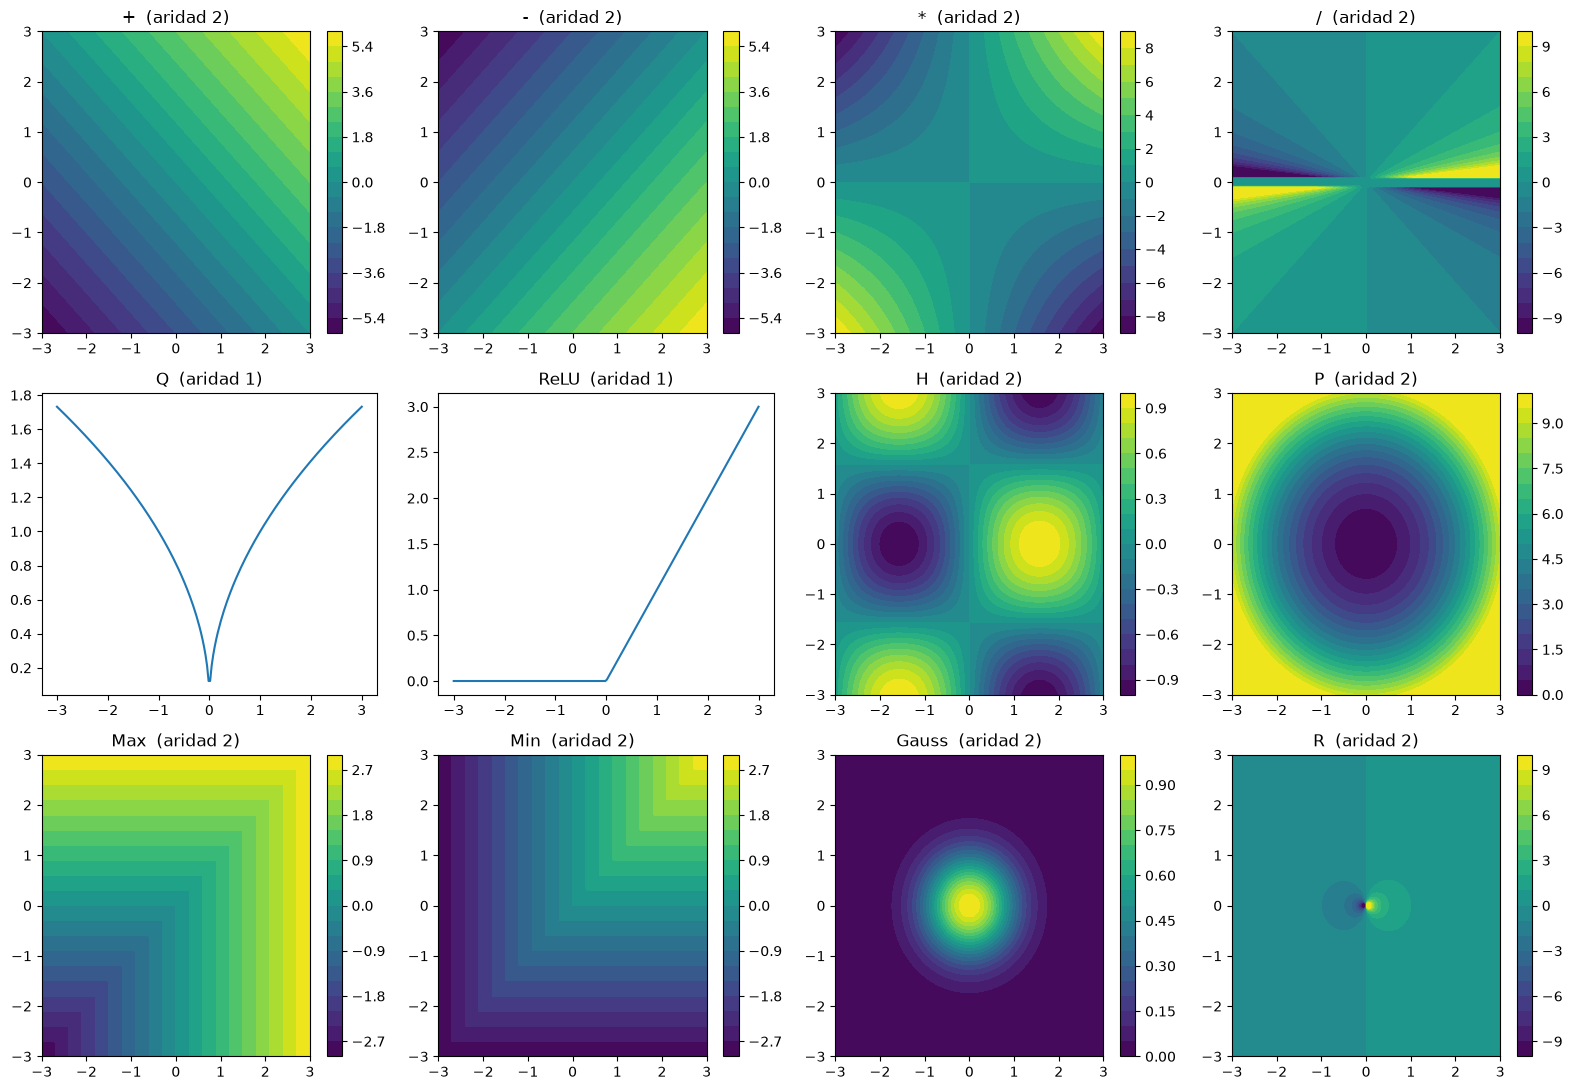

In [4]:
from gepkarva import HPFUNCION
x = np.linspace(-3, 3, 200)
X_, Y_ = np.meshgrid(x, x)
fig, axes = plt.subplots(3, 4, figsize=(16, 11))
for ax, (f, ar) in zip(axes.ravel(), HPFUNCION.items()):
    if ar == 1:
        ax.plot(x, aplicar(f, [x]))
    else:
        Zf = aplicar(f, [X_.ravel(), Y_.ravel()]).reshape(X_.shape)
        cs = ax.contourf(X_, Y_, np.clip(Zf, -10, 10), 20, cmap="viridis")
        fig.colorbar(cs, ax=ax)
    ax.set_title(f"{f}  (aridad {ar})")
plt.tight_layout(); plt.show()

# Objeto gen
---

Un gen tiene longitud `largo_gen = h + t`: la **cabeza** (`h`) admite funciones y terminales, y la **cola** (`t = h·(aridad_max−1)+1`) sólo terminales, lo que garantiza que cualquier secuencia se pueda leer como un árbol válido. Los enteros se traducen con `correspondencia`: primero funciones, luego variables `X1..Xn`, luego constantes.

h = 15 | t = 16 | largo_gen = 31
n_f = 12 | n_term = 14 | n_simb = 26
karva (enteros): [ 2 22  6  7  3  3 13  4  6 20  9  6 17  8 25 18 24 23 20 22 25 18 24 18
 14 23 25 13 21 24 12]
karva (símbolos): * 1 H P / / X2 Q H X9 Min H X6 Max 3.14  |  X7 0.5 2 X9 1 3.14 X7 0.5 X7 X3 2 3.14 X2 X10 0.5 X1
es_lineal(): False
adj(): {0: [1, 2], 2: [3, 4], 3: [5, 6], 4: [7, 8], 5: [9, 10], 7: [11], 8: [12, 13], 10: [14, 15], 11: [16, 17], 13: [18, 19]}


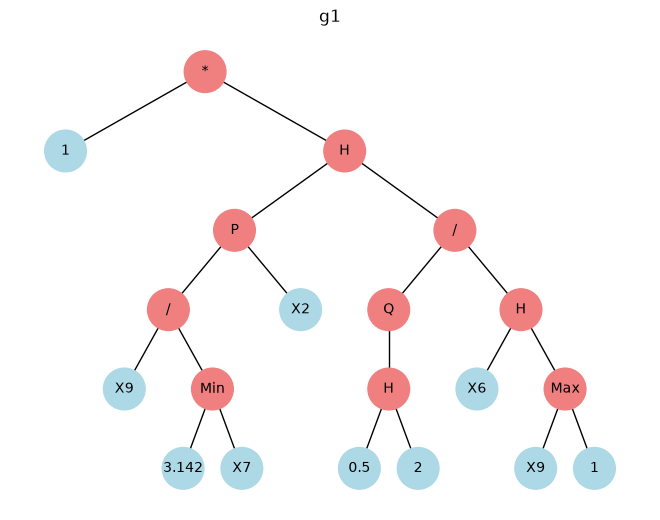

In [5]:
g1 = gen(n_vars=10, h=15)
g1.aleatorio(rng)
print("h =", g1.h, "| t =", g1.t, "| largo_gen =", g1.largo_gen)
print("n_f =", g1.n_f, "| n_term =", g1.n_term, "| n_simb =", g1.n_simb)
print("karva (enteros):", g1.karva)
print("karva (símbolos):", decodificar(g1))
print("es_lineal():", g1.es_lineal())
print("adj():", g1.adj())
g1.plot_gen(); plt.title("g1"); plt.show()

`aleatorio` reintenta hasta que el gen contiene alguna función **no lineal** (índices ≥ 2 en `funciones`), y la raíz sea una función. Comprobamos con 500 genes:

Algún gen lineal: False
Cola sólo con terminales: True
Nodos usados: media 13.7, min 2, max 29 (largo_gen = 31)


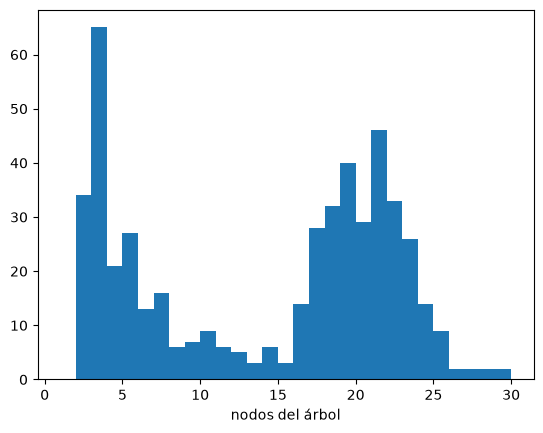

In [6]:
genes = []
for _ in range(500):
    g = gen(10, 15); g.aleatorio(rng); genes.append(g)
print("Algún gen lineal:", any(g.es_lineal() for g in genes))
print("Cola sólo con terminales:", all((g.karva[g.h:] >= g.n_f).all() for g in genes))
# Nº de nodos usados realmente (los que están en el árbol)
usados = [len(g.grafo()) for g in genes]
print(f"Nodos usados: media {np.mean(usados):.1f}, min {min(usados)}, max {max(usados)} (largo_gen = {g1.largo_gen})")
plt.hist(usados, bins=range(1, max(usados) + 2)); plt.xlabel("nodos del árbol"); plt.show()

### Evaluación
`evaluar(Z)` recibe una matriz `(N, n_vars)` y devuelve un vector `(N,)` (con `nan→0` y recorte a ±1e6).

shape: (354,) | primeros valores: [0.4552 0.4552 0.4552 0.4552 0.4554]
karva: + *  |  X1 X2 2 X1 X1 | adj: {0: [1, 2], 1: [3, 4]}
evaluar: [ 5. 10.] | esperado: [ 5. 10.]


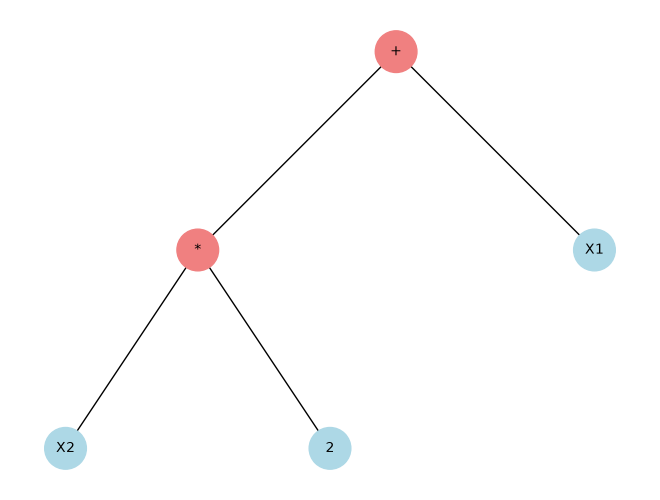

In [7]:
cols = [c for c in dfD_train.columns if c != "target"]
Xtr = dfD_train[cols].to_numpy()
ytr = dfD_train["target"].to_numpy()
v = g1.evaluar(Xtr)
print("shape:", v.shape, "| primeros valores:", np.round(v[:5], 4))

# Verificación manual con un gen escrito a mano
gm = gen(n_vars=3, h=2)
# '+' (idx 0) con hijos [*, X1]; '*' (idx 2) con hijos [X2, 2.0]  =>  (X2 * 2) + X1
X1, X2 = gm.n_f, gm.n_f + 1
cte2 = gm.n_f + gm.n_vars + 1   # constante 2.0
gm.karva = np.array([0, 2, X1, X2, cte2, X1, X1])
print("karva:", decodificar(gm), "| adj:", gm.adj())
Zt = np.array([[1., 2., 3.], [0., 5., 1.]])
print("evaluar:", gm.evaluar(Zt), "| esperado:", Zt[:, 0] + Zt[:, 1] * 2)
gm.plot_gen(); plt.show()

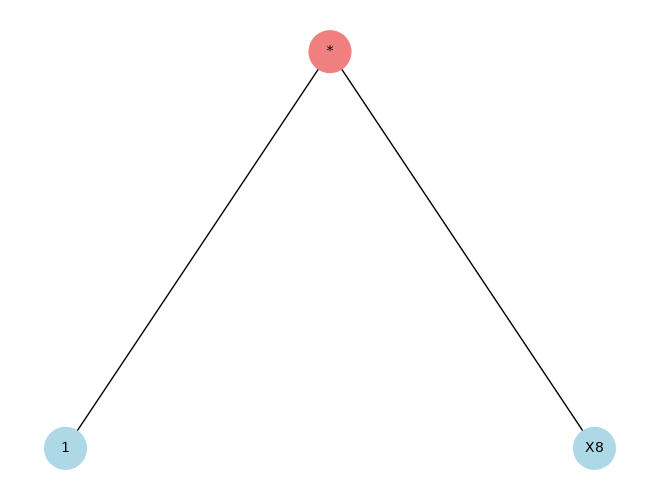

In [8]:
mutacion(g1, 0.2, rng)
g1.plot_gen()
plt.show()

### Copia y guardado en JSON

In [9]:
c = g1.copy()
c.karva[0] = 99                       # modificar la copia no toca el original
print("original intacto:", g1.karva[0] != 99)
ruta = g1.save_as_json("ejemplos/ejemplo_gen")
g_load = load_from_json("ejemplos/ejemplo_gen")
print(ruta)
print("recarga idéntica:", np.array_equal(g_load.karva, g1.karva),
      "| mismas evaluaciones:", np.allclose(g_load.evaluar(Xtr), g1.evaluar(Xtr)))

original intacto: True
ejemplos/ejemplo_gen.json
recarga idéntica: True | mismas evaluaciones: True


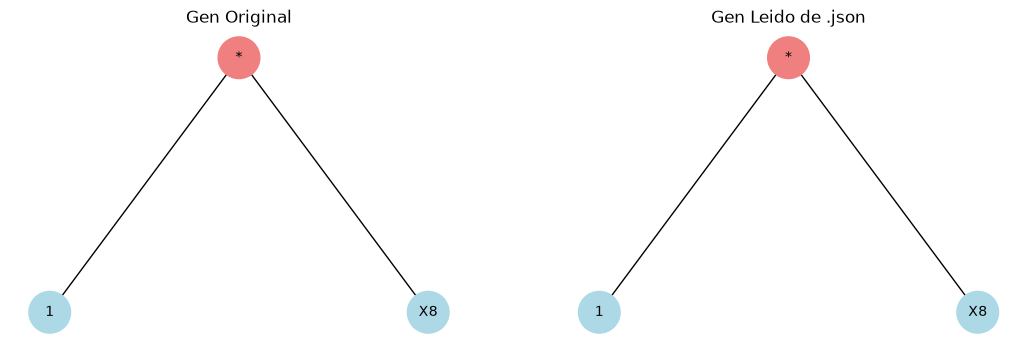

In [10]:
# COMPARAMOS LOS PLOTS
dos_gen(g1, g_load, 'Gen Original', 'Gen Leido de .json')

## Operaciones de genes

---

### Mutación puntual
Cada posición muta con probabilidad `p`. En la cabeza el símbolo nuevo es cualquiera (sesgado hacia funciones no lineales); en la cola, sólo terminales. **Modifica el gen en el sitio.**

p=0.0: 0/31 posiciones distintas | cola válida: True
p=0.2: 11/31 posiciones distintas | cola válida: True
p=1.0: 27/31 posiciones distintas | cola válida: True

antes  : * 1 X8 P / * X2 Q H X9 Min H + Max /  |  X7 X6 2 X9 X9 3.14 X7 0.5 X7 X3 2 3.14 X2 X10 2 X1
después: * 1 X8 P / * + 3.14 P X9 Min 0.5 X8 Max /  |  X7 X10 2 X7 0.5 3.14 3.14 0.5 X7 X3 3.14 X1 X2 X10 2 X1


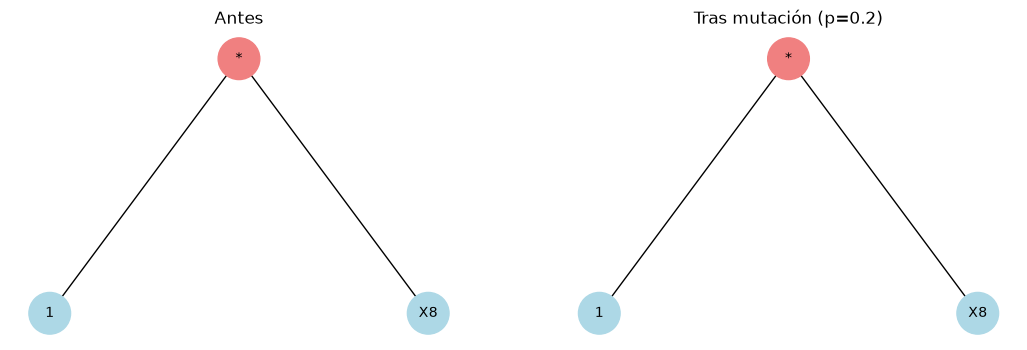

In [11]:
for p in (0.0, 0.2, 1.0):
    a = g1.copy(); mutacion(a, p, rng)
    cambios = int((a.karva != g1.karva).sum())
    print(f"p={p}: {cambios}/{a.largo_gen} posiciones distintas | cola válida: {(a.karva[a.h:] >= a.n_f).all()}")

a = g1.copy(); mutacion(a, 0.2, rng)
print("\nantes  :", decodificar(g1)); print("después:", decodificar(a))
dos_gen(g1, a, "Antes", "Tras mutación (p=0.2)")

### Transposición de elementos (IS)
Se copia un fragmento de `long` símbolos de `g2` y se inserta en la cabeza de `g1` (posición ≥ 1, la raíz no se toca); la cabeza se trunca a `h`. La cola no cambia.

g1 : * 1 X8 P / * X2 Q H X9 Min H + Max /  |  X7 X6 2 X9 X9 3.14 X7 0.5 X7 X3 2 3.14 X2 X10 2 X1
g2 : Max / X5 0.5 + 0.5 X3 Q X3 R - Q Max P X3  |  1 X10 X5 1 X6 X1 X6 X4 X8 2 X9 0.5 X9 0.5 3.14 X6
IS : * 1 X8 P / * X2 Q H X9 Min Max P X3 H  |  X7 X6 2 X9 X9 3.14 X7 0.5 X7 X3 2 3.14 X2 X10 2 X1
cola intacta: True


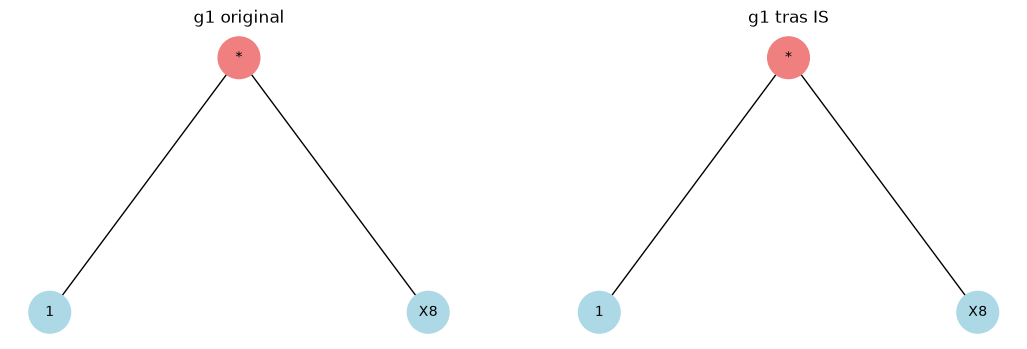

In [12]:
g2 = gen(10, 15); g2.aleatorio(rng)
a = g1.copy()
transposicion_de_elementos(a, g2, rng, long=3)
print("g1 :", decodificar(g1)); print("g2 :", decodificar(g2)); print("IS :", decodificar(a))
print("cola intacta:", np.array_equal(a.karva[a.h:], g1.karva[g1.h:]))
dos_gen(g1, a, "g1 original", "g1 tras IS")

### Transposición de raíz
Se toma un fragmento que **empieza por una función** de `g2` y se coloca en la raíz de `g1`, desplazando el resto de la cabeza.

g1   : * 1 X8 P / * X2 Q H X9 Min H + Max /  |  X7 X6 2 X9 X9 3.14 X7 0.5 X7 X3 2 3.14 X2 X10 2 X1
g2   : Max / X5 0.5 + 0.5 X3 Q X3 R - Q Max P X3  |  1 X10 X5 1 X6 X1 X6 X4 X8 2 X9 0.5 X9 0.5 3.14 X6
raíz : P X3 1 * 1 X8 P / * X2 Q H X9 Min H  |  X7 X6 2 X9 X9 3.14 X7 0.5 X7 X3 2 3.14 X2 X10 2 X1


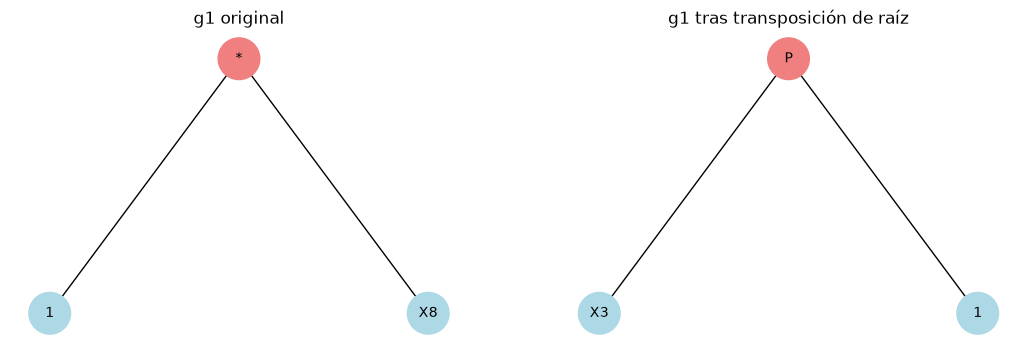

In [13]:
a = g1.copy()
transposicion_de_raiz(a, g2, rng, long=3)
print("g1   :", decodificar(g1)); print("g2   :", decodificar(g2)); print("raíz :", decodificar(a))
dos_gen(g1, a, "g1 original", "g1 tras transposición de raíz")

# Objeto Cromosoma
---

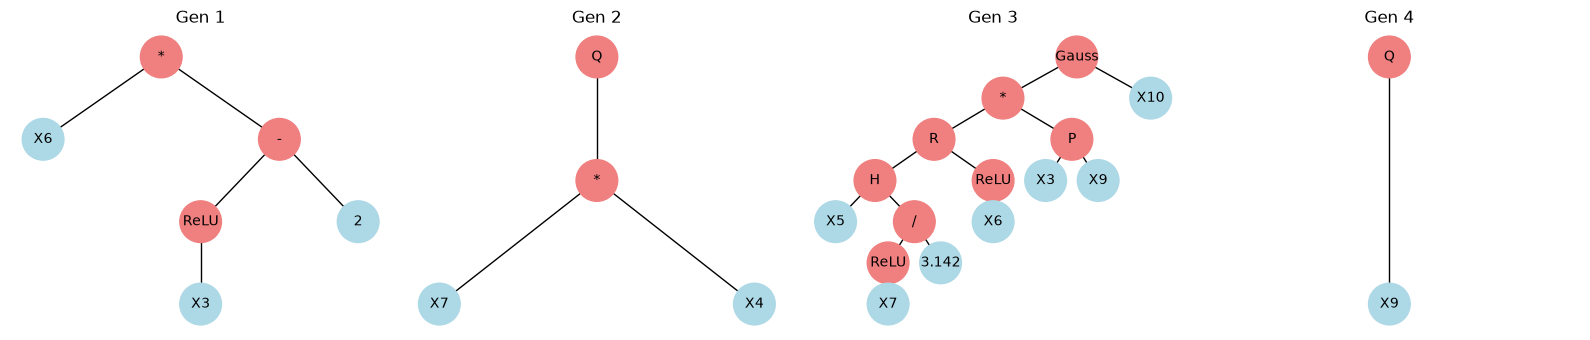

In [14]:
C = Cromosoma(n_vars=10, h=15, n_gen=4)
C.aleatorio(rng)
fig, axes = C.plot_cromosoma()
plt.show()

Un cromosoma es una lista de genes. `evaluar` devuelve una matriz `(n_gen, N)` — cada gen será un **nuevo atributo** para la regresión. `toarray` concatena los karva y `update` reparte una secuencia entre los genes.

In [15]:
F = C.evaluar(Xtr)
print("evaluar:", F.shape)
arr = C.toarray()
print("toarray:", arr.shape, "= n_gen * largo_gen =", C.n_gen * C.largo_gen)
C.update(arr[::-1].copy())   # reparte una secuencia (invertida) entre los genes
print("update ok:", np.array_equal(C.toarray(), arr[::-1]))
C.update(arr)                # restauramos

evaluar: (354, 4)
toarray: (124,) = n_gen * largo_gen = 124
update ok: True


In [16]:
F.reshape(-1,1)
F.shape
Xtr.shape

(354, 10)

### Recombinaciones
Trabajan sobre la secuencia completa de los cromosomas y modifican ambos **en el sitio**.

In [17]:
def difs(a, b): return int((a != b).sum())
C2 = Cromosoma(10, 15, 4); C2.aleatorio(rng)
A, B = C.toarray(), C2.toarray()

# recombinación simple: intercambia todo lo que hay a partir de un punto
c1 = Cromosoma(10, 15, 4); c1.update(A.copy()); c2 = Cromosoma(10, 15, 4); c2.update(B.copy())
recombinacion_simple(c1, c2, rng)
print("simple     -> posiciones distintas c1:", difs(c1.toarray(), A), "| c2:", difs(c2.toarray(), B))

# multipunto: intercambia un tramo entre dos puntos
c1.update(A.copy()); c2.update(B.copy())
recombinacion_multipunto(c1, c2, rng)
print("multipunto -> posiciones distintas c1:", difs(c1.toarray(), A), "| c2:", difs(c2.toarray(), B))

# de cromosomas: intercambia un gen entero
c1.update(A.copy()); c2.update(B.copy())
recombinacion_de_cromosomas(c1, c2, rng)
print("de genes   -> genes cambiados c1:", [i for i in range(4) if not np.array_equal(c1.sec_genes[i].karva, A[i*C.largo_gen:(i+1)*C.largo_gen])])

simple     -> posiciones distintas c1: 62 | c2: 62
multipunto -> posiciones distintas c1: 6 | c2: 6
de genes   -> genes cambiados c1: [0]


**Comprobación de integridad:** tras muchas aplicaciones sucesivas de todos los operadores, todo gen sigue siendo válido (cola con terminales) y evaluable.

In [18]:
ok = True
for _ in range(300):
    a, b = gen(10, 15), gen(10, 15); a.aleatorio(rng); b.aleatorio(rng)
    mutacion(a, 0.3, rng); transposicion_de_elementos(a, b, rng); transposicion_de_raiz(a, b, rng)
    p, q = Cromosoma(10, 15, 3), Cromosoma(10, 15, 3); p.aleatorio(rng); q.aleatorio(rng)
    recombinacion_simple(p, q, rng); recombinacion_multipunto(p, q, rng); recombinacion_de_cromosomas(p, q, rng)
    for x in [a, b] + p.sec_genes + q.sec_genes:
        ok &= len(x.karva) == x.largo_gen and bool((x.karva[x.h:] >= x.n_f).all())
        ok &= bool(np.isfinite(x.evaluar(Xtr[:20])).all())
print("Todos los individuos válidos:", ok)

Todos los individuos válidos: True


## GUARDAR CROMOSOMAS


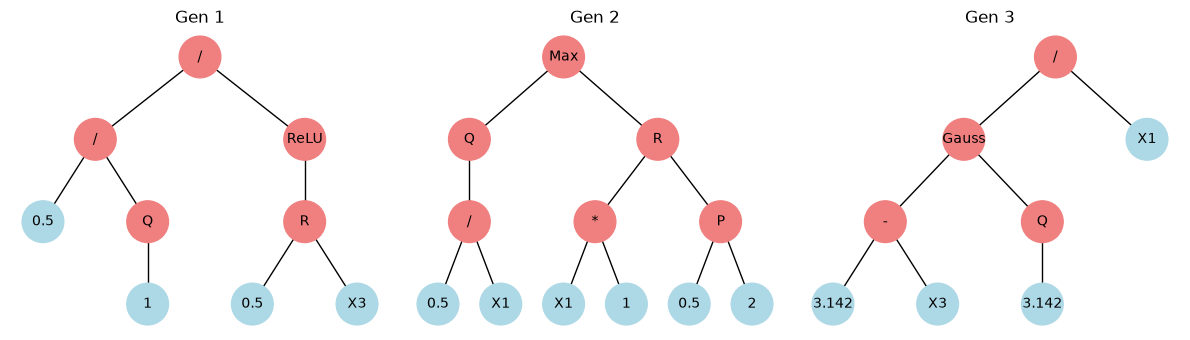

In [19]:
c1 = Cromosoma(4, 6, n_gen=3)
c1.aleatorio(rng)
c1.guardar_cromosoma('ejemplos/Cromosoma_ejemplo')
c1.plot_cromosoma()
plt.show()

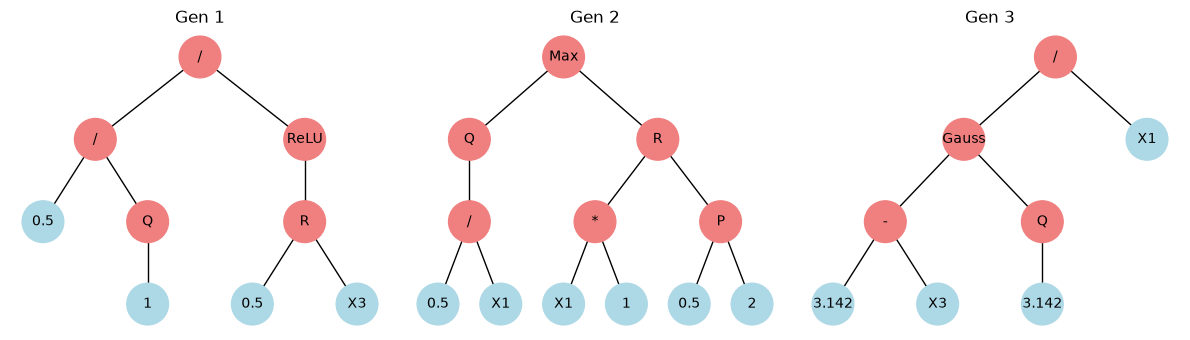

In [21]:
c1_load = Cromosoma.cargar_cromosoma('ejemplos/Cromosoma_ejemplo')
c1_load.plot_cromosoma()
plt.show()